# c₂ distribution for every symmetry mode (MnBi₂Te₄ T₂⁻ 1-4, Y₂Ir₂O₇ Γ₂⁻ 1-3)

Companion to the paper draft `../figures/c2_distribution.ipynb` (which shows MBT mode 3 and YIO Ir only; unchanged in
layout). Same data and conventions: c₂(**k**) is the integrand of Eq. (4curv-reduced), ∂θ/∂Q = ∫ c₂ d³k over the unit
cube of reduced coordinates.

* **MnBi₂Te₄** (one row per T₂⁻ basis pattern: Mn, Bi, Te1, Te2; 1e-10 production tubes, Q = 0.01 Å, half-width 3,
  m 4, 8 planes): c₂ on the plane through Γ (u₃ = 0) and through Z (u₃ = ½), plotted against Cartesian (k_x, k_y), with
  direct-gap contours; and the fraction of ∂θ/∂Q within k⊥ of the k_z axis with the shell-mean c₂.
* **Y₂Ir₂O₇** (one panel per Γ₂⁻ pattern: Y, Ir, O48f): c₂ on the (110) plane through Γ, periodic cubic interpolation
  of the 10³ production mesh (self-test base, series windows), clipped to the first zone; and the concentration curves.

`END` picks the estimate: 0 = momentum-space quantities of the undistorted structure (the values in the paper's MBT
tables), 1 = displaced structure, "mean".


In [1]:
# ---- settings
from pathlib import Path
ROOT = Path("/Users/treycole/Repos/axion-phonon")
DATA = ROOT / "data"
MBT_TUBES = {1: DATA / "MnBi2Te4/archive/julia_amn/T2-_p1_Q0.01/dtheta",   # klist.npz + chunks/
             2: DATA / "MnBi2Te4/archive/julia_amn/T2-_p2_Q0.01/dtheta",
             3: DATA / "MnBi2Te4/archive/dtheta_tube_conv1e-10_k8_2026-10-19/mode3_Q0p01",
             4: DATA / "MnBi2Te4/archive/julia_amn/T2-_p4_Q0.01/dtheta"}
MBT_LABELS = {1: "Mn", 2: "Bi", 3: "Te1", 4: "Te2"}
MBT_WIN = DATA / "MnBi2Te4/archive/base/lda/w90_sp_d_k8_selftest_conv1e-10_214301/MnBi2Te4.win"   # cell
MBT_PLANES = {0: r"$\Gamma$ plane", 4: "Z plane"}   # plane index of the 8 (u3 = 0, 1/2) -> title
MBT_MAP_HALF = 0.25                  # 1/Å, half-width of the maps
YIO_C2 = {m: next((DATA / "Y2Ir2O7/phonon/GM2-").glob(f"mode{m}/Q_0.01A/lda/w90_trial02_ampwin10_2026-10-18_*/nk_sweep_tif_shared_ws_selftestbase/nk_10.npz"))
          for m in (1, 2, 3)}
YIO_WIN = DATA / "Y2Ir2O7/base/lda/w90_trial02_selftest_ampwin10_214249/Y2Ir2O7.win"
YIO_LABELS = {1: "Y", 2: "Ir", 3: r"O$_{48f}$"}
YIO_GRID = 301                       # points per side of the interpolation grid
END = 0                              # 0: undistorted end, 1: displaced end, "mean"
FONT_SIZE = 8
SAVE_MBT = DATA / "MnBi2Te4/studies/c2_distribution_modes.png"   # or None
SAVE_YIO = DATA / "Y2Ir2O7/phonon/GM2-/c2_distribution_modes.png"   # or None
# ---------------


In [2]:
# ---- data
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import SymLogNorm, TwoSlopeNorm
from scipy.ndimage import map_coordinates
from itertools import permutations, product

def cell(win):
    lines = Path(win).read_text().splitlines()
    i = next(j for j, line in enumerate(lines) if line.strip().lower() == "begin unit_cell_cart")
    rows = [line.split() for line in lines[i + 1:i + 5] if line.split() and line.split()[0].lower() not in ("ang", "bohr")][:3]
    A = np.array(rows, float)
    return A, 2 * np.pi * np.linalg.inv(A).T                      # rows a_i (Å), rows b_i (1/Å)

def pick(c2):
    return c2.real.mean(axis=-1) if END == "mean" else c2[..., END].real

# MnBi2Te4: the four tubes share one k list (checked); quadrature weights as assemble_tube.py
_, B_m = cell(MBT_WIN)
zhat = B_m.sum(0) / np.linalg.norm(B_m.sum(0))                    # k_z: the tube axis t(b1 + b2 + b3)
kl = np.load(MBT_TUBES[1] / "klist.npz")
nk, M, N3 = int(kl["nk"]), int(kl["M"]), int(kl["n3"])
w_m = np.where(kl["level"] == 0, (1 / nk) ** 2, (1 / nk / M) ** 2) / N3
k_red = (kl["k"] + 0.5) % 1 - 0.5
images = np.array(np.meshgrid(*[[-1, 0, 1]] * 3, indexing="ij")).reshape(3, -1).T
kc_all = (k_red[:, None, :] + images[None]) @ B_m
perp_all = np.linalg.norm(kc_all - (kc_all @ zhat)[..., None] * zhat, axis=-1)
best = perp_all.argmin(1)
kc_m = kc_all[np.arange(len(best)), best]                          # the image nearest the axis
kperp = perp_all.min(1)
bp = [B_m[j] - (B_m[j] @ zhat) * zhat for j in (0, 1)]
sin_ab = np.sqrt(1 - (bp[0] @ bp[1] / np.linalg.norm(bp[0]) / np.linalg.norm(bp[1])) ** 2)
BOX_INRADIUS = (int(kl["half"]) + 0.5) / nk * np.linalg.norm(bp[0]) * sin_ab
c2_m, gap_m, dth_m = {}, {}, {}
for m, tube in MBT_TUBES.items():
    assert np.array_equal(np.load(tube / "klist.npz")["k"], kl["k"]), f"mode {m}: different k list"
    c, g = np.full(len(kl["k"]), np.nan), np.full(len(kl["k"]), np.nan)
    for f in sorted((tube / "chunks").glob("chunk_*")):
        z = np.load(f)
        c[z["idx"]] = pick(z["c2"])
        g[z["idx"]] = z["gap"][:, 1 if END == 1 else 0]
    assert not np.isnan(c).any(), f"mode {m}: missing chunks"
    c2_m[m], gap_m[m], dth_m[m] = c, g, (w_m * c).sum()
    o = np.argsort(kperp)
    cum = np.cumsum((w_m * c)[o]) / dth_m[m]
    print(f"MBT mode {m} ({MBT_LABELS[m]}): ∂θ/∂Q = {dth_m[m]:+.4f} rad/Å (END {END!r}, base tube, not k-corrected); "
          + ", ".join(f"k⊥ < {r}: {100 * cum[np.searchsorted(kperp[o], r) - 1]:.1f}%" for r in (0.05, 0.1, 0.2)))

# Y2Ir2O7: 10³ mesh, k = n / nk in reduced coordinates
c2_y = {m: pick(np.asarray(np.load(f, allow_pickle=True)["c2_density"])) for m, f in YIO_C2.items()}
A_y, B_y = cell(YIO_WIN)
for m, c in c2_y.items():
    print(f"YIO pattern {m} ({YIO_LABELS[m]}): ∂θ/∂Q = {c.mean():+.6f} rad/Å on {c.shape[0]}³")


MBT mode 1 (Mn): ∂θ/∂Q = -1.9881 rad/Å (END 0, base tube, not k-corrected); k⊥ < 0.05: 75.6%, k⊥ < 0.1: 100.3%, k⊥ < 0.2: 106.0%
MBT mode 2 (Bi): ∂θ/∂Q = +3.8411 rad/Å (END 0, base tube, not k-corrected); k⊥ < 0.05: 48.8%, k⊥ < 0.1: 93.0%, k⊥ < 0.2: 102.3%
MBT mode 3 (Te1): ∂θ/∂Q = +6.4344 rad/Å (END 0, base tube, not k-corrected); k⊥ < 0.05: 45.9%, k⊥ < 0.1: 85.3%, k⊥ < 0.2: 97.4%
MBT mode 4 (Te2): ∂θ/∂Q = -4.5521 rad/Å (END 0, base tube, not k-corrected); k⊥ < 0.05: 62.0%, k⊥ < 0.1: 98.5%, k⊥ < 0.2: 103.2%
YIO pattern 1 (Y): ∂θ/∂Q = -0.017134 rad/Å on 10³
YIO pattern 2 (Ir): ∂θ/∂Q = +0.054677 rad/Å on 10³
YIO pattern 3 (O$_{48f}$): ∂θ/∂Q = +0.063787 rad/Å on 10³


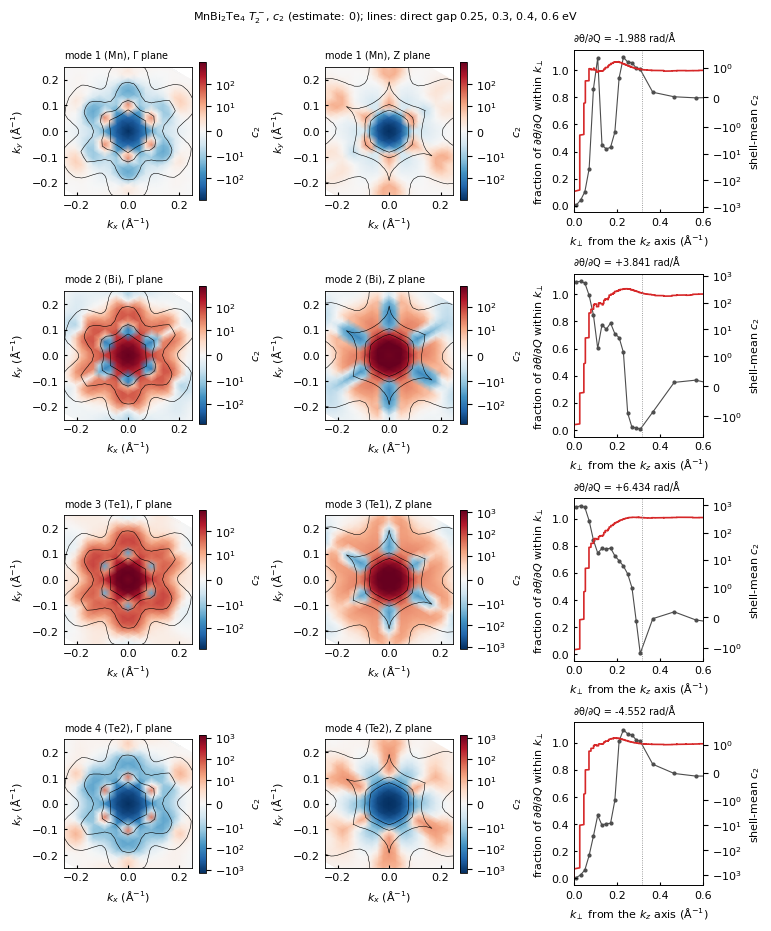

In [3]:
# ---- MnBi2Te4: one row per symmetry mode
plt.rcParams.update({"font.size": FONT_SIZE, "axes.linewidth": 0.6})
fig, axes = plt.subplots(len(MBT_TUBES), 3, figsize=(7.6, 2.3 * len(MBT_TUBES)), layout="constrained")
for row, (m, c) in zip(axes, c2_m.items()):
    for ax, (plane, pname) in zip(row[:2], MBT_PLANES.items()):
        sel = (kl["plane"] == plane) & (kl["level"] >= 1)
        x, y = kc_m[sel, 0], kc_m[sel, 1]
        vmax = np.abs(c[sel]).max()
        im = ax.tripcolor(x, y, c[sel], shading="gouraud", cmap="RdBu_r", norm=SymLogNorm(linthresh=10, vmin=-vmax, vmax=vmax))
        ax.tricontour(x, y, gap_m[m][sel], levels=[0.25, 0.3, 0.4, 0.6], colors="k", linewidths=0.4)
        ax.set(xlim=(-MBT_MAP_HALF, MBT_MAP_HALF), ylim=(-MBT_MAP_HALF, MBT_MAP_HALF), aspect="equal",
               xlabel=r"$k_x$ (Å$^{-1}$)", ylabel=r"$k_y$ (Å$^{-1}$)")
        fig.colorbar(im, ax=ax, label=r"$c_2$", shrink=0.85)
        ax.set_title(f"mode {m} ({MBT_LABELS[m]}), {pname}", loc="left", fontsize=FONT_SIZE - 1)
    ax = row[2]
    o = np.argsort(kperp)
    ax.plot(kperp[o], np.cumsum((w_m * c)[o]) / dth_m[m], color="C3", lw=1.2)
    ax.axvline(BOX_INRADIUS, color="0.5", lw=0.6, ls=":")
    ax.set(xlim=(0, 0.6), ylim=(-0.05, 1.15), xlabel=r"$k_\perp$ from the $k_z$ axis (Å$^{-1}$)",
           ylabel=r"fraction of $\partial\theta/\partial Q$ within $k_\perp$")
    ax2 = ax.twinx()
    edges = np.r_[np.arange(0, BOX_INRADIUS, 0.02), np.arange(BOX_INRADIUS, kperp.max() + 0.1, 0.1)]
    shell = np.digitize(kperp, edges) - 1
    mid, avg = [], []
    for g in np.unique(shell):
        s = shell == g
        mid.append(0.5 * (edges[g] + edges[g + 1])); avg.append((w_m[s] * c[s]).sum() / w_m[s].sum())
    ax2.plot(mid, avg, "o-", color="0.3", lw=0.8, ms=2)
    ax2.set_yscale("symlog", linthresh=1)
    ax2.set_ylabel(r"shell-mean $c_2$")
    ax.set_zorder(ax2.get_zorder() + 1); ax.patch.set_visible(False)
    ax.set_title(f"∂θ/∂Q = {dth_m[m]:+.3f} rad/Å", loc="left", fontsize=FONT_SIZE - 1)
for ax in axes.ravel():
    ax.tick_params(direction="in", length=2, which="both")
fig.suptitle(f"MnBi$_2$Te$_4$ $T_2^-$, $c_2$ (estimate: {END!r}); lines: direct gap 0.25, 0.3, 0.4, 0.6 eV", fontsize=FONT_SIZE)
if SAVE_MBT:
    fig.savefig(SAVE_MBT, dpi=250)
plt.show()


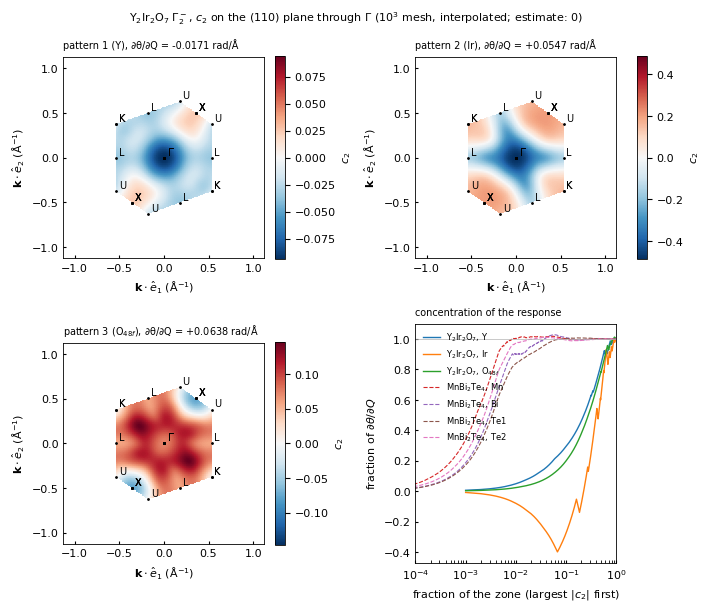

In [4]:
# ---- Y2Ir2O7: (110) plane through Γ for each pattern, and the concentration curves
e1 = B_y[0] / np.linalg.norm(B_y[0])
e2 = B_y[1] - (B_y[1] @ e1) * e1
e2 /= np.linalg.norm(e2)
normal = np.cross(e1, e2)
R = 1.05 * np.linalg.norm(B_y, axis=1).max()
s = np.linspace(-R, R, YIO_GRID)
S, T = np.meshgrid(s, s, indexing="xy")
kc = S[..., None] * e1 + T[..., None] * e2
kr = kc @ np.linalg.inv(B_y)
G = np.array(np.meshgrid(*[range(-2, 3)] * 3, indexing="ij")).reshape(3, -1).T @ B_y
G = G[np.linalg.norm(G, axis=1) > 1e-9]
inside = np.all(np.einsum("ijk,gk->ijg", kc, G) <= 0.5 * (G ** 2).sum(1), axis=-1)
a = np.linalg.norm(A_y[0]) * np.sqrt(2)                          # cubic lattice constant
pts = {r"$\Gamma$": (0, 0, 0), "X": (0, 0, 1), "L": (0.5, 0.5, 0.5), "K": (0.75, 0.75, 0), "U": (0.25, 0.25, 1), "W": (0.5, 0, 1)}
labels_in_plane = []
for name, p in pts.items():
    for perm in set(permutations(p)):
        for sg in product((1, -1), repeat=3):
            k = 2 * np.pi / a * np.array(perm) * sg
            if abs(k @ normal) < 1e-6 and np.all(np.abs(k @ np.array([e1, e2]).T) <= R):
                labels_in_plane.append((name, k @ e1, k @ e2))

fig, axes = plt.subplots(2, 2, figsize=(7.0, 6.0), layout="constrained")
for ax, (m, c) in zip(axes.ravel()[:3], c2_y.items()):
    n = c.shape[0]
    mp = np.where(inside, map_coordinates(c, (kr % 1.0 * n).transpose(2, 0, 1), order=3, mode="grid-wrap"), np.nan)
    v = np.nanmax(np.abs(mp))
    im = ax.pcolormesh(S, T, mp, cmap="RdBu_r", norm=TwoSlopeNorm(0, -v, v), shading="auto")
    for name, u, w in labels_in_plane:
        ax.plot(u, w, "k.", ms=2)
        ax.annotate(name, (u, w), xytext=(2, 2), textcoords="offset points", fontsize=FONT_SIZE - 1)
    ax.set(aspect="equal", xlabel=r"$\mathbf{k}\cdot\hat e_1$ (Å$^{-1}$)", ylabel=r"$\mathbf{k}\cdot\hat e_2$ (Å$^{-1}$)")
    fig.colorbar(im, ax=ax, label=r"$c_2$", shrink=0.85)
    ax.set_title(f"pattern {m} ({YIO_LABELS[m]}), ∂θ/∂Q = {c.mean():+.4f} rad/Å", loc="left", fontsize=FONT_SIZE - 1)
ax = axes[1, 1]
for m, c in c2_y.items():
    f = c.ravel()[np.argsort(-np.abs(c.ravel()))]
    ax.plot(np.arange(1, f.size + 1) / f.size, np.cumsum(f) / f.sum(), lw=1, label=f"Y$_2$Ir$_2$O$_7$, {YIO_LABELS[m]}")
for m, c in c2_m.items():
    o = np.argsort(-np.abs(c))
    ax.plot(np.cumsum(w_m[o]), np.cumsum((w_m * c)[o]) / dth_m[m], lw=0.8, ls="--", label=f"MnBi$_2$Te$_4$, {MBT_LABELS[m]}")
ax.axhline(1, color="0.7", lw=0.5)
ax.set(xscale="log", xlim=(1e-4, 1), xlabel="fraction of the zone (largest $|c_2|$ first)", ylabel=r"fraction of $\partial\theta/\partial Q$")
ax.legend(fontsize=FONT_SIZE - 2, frameon=False, loc="upper left")
ax.set_title("concentration of the response", loc="left", fontsize=FONT_SIZE - 1)
for ax in axes.ravel():
    ax.tick_params(direction="in", length=2, which="both")
fig.suptitle(f"Y$_2$Ir$_2$O$_7$ $\\Gamma_2^-$, $c_2$ on the (110) plane through $\\Gamma$ (10$^3$ mesh, interpolated; estimate: {END!r})", fontsize=FONT_SIZE)
if SAVE_YIO:
    fig.savefig(SAVE_YIO, dpi=250)
plt.show()
plt.rcdefaults()
